# 02: Annotation accuracy

*Does each graph's own labelling survive a check from outside the graph?*

| Sub-metric | Definition | Quantification | Scoring |
|---|---|---|---|
| **Entity validity** | Of the nodes whose identifier shape can be adjudicated, the fraction whose shape fits their declared type | identifier shapes in `config/id_schemes.yaml` | direct, 0-1 |
| **Relational consistency** | Of the edges both of whose endpoints are adjudicable, the fraction where both shapes fit the types the edge declares | the same shapes, applied to both endpoints | direct, 0-1 |

The dimension score is the equal-weighted mean of the two.

**Reported, not scored.** Registry resolution (does the identifier resolve to a live entry *of that type* in a reference database), node index uniqueness, and relation exclusivity.

The arbiter is `config/id_schemes.yaml`, so the judgement comes from **outside the graph being judged** and every graph is held to one rule. An identifier matching no declared shape is neither right nor wrong: it is excluded from the denominator and counted separately, so the score must be read beside `nodes_judged_pct` and `edges_checkable_pct`.

**Inputs:** `config/kgs.yaml` · `config/id_schemes.yaml` · `data/crosswalks/` · KG edge and node files

**Outputs:** `results/{figures,tables}/02_annotation_accuracy/` · `results/checkpoints/02_annotation_accuracy.pkl`

Design notes and justifications: [`README.md`](README.md)

## Set-up

Every graph in `config/kgs.yaml` is checked against the identifier shapes in `config/id_schemes.yaml`. Nothing here samples or perturbs the graph, so no seed affects the scored metrics.

In [1]:
# Pick up edits to src/ without restarting the kernel. Without this, editing a
# module after it has been imported leaves the kernel holding the old version,
# which surfaces as a confusing ImportError for a name that is plainly on disk.
try:
    get_ipython().run_line_magic('load_ext', 'autoreload')
    get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass                      # not running under IPython (headless runner, plain python)

import gc
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Locate the repo root from any depth, then make the package importable.
# (`pip install -e .` also works and makes this block a no-op.)
_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'config' / 'kgs.yaml').exists())
if str(_root / 'src') not in sys.path:
    sys.path.insert(0, str(_root / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from biokgsuite.io import Outputs, assert_full_panel, find_config, load_config, load_kg
from biokgsuite.io.resolve import IdResolver
from biokgsuite.io.schemes import IdSchemes
from biokgsuite.stats.annotation import (
    REGISTRY_CHECKED, checkability_breakdown, entity_validity,
    identifier_ambiguity, node_index_uniqueness, pool_by_canonical,
    relation_exclusivity, relational_consistency, resolve_types)
from biokgsuite.stats.coverage import schema_coverage
from biokgsuite.viz.primitives import coverage_heatmap
from biokgsuite.viz.style import setup_style

setup_style()

In [ ]:
config = load_config(find_config(_root))
BASE   = config['_base_dir']

# Every figure, table and checkpoint goes through `out`, so results land in
# results/{figures,tables}/02_annotation_accuracy/ and
# results/checkpoints/02_annotation_accuracy.pkl.
out = Outputs('02_annotation_accuracy', BASE)

# A run that scores fewer graphs than config/kgs.yaml declares is a
# different experiment, not a smaller one, so it has to be asked for.
ALLOW_PARTIAL_PANEL = False


### Loading

In [2]:
# Free any KG state left by an earlier notebook before loading again, so the
# two sets never coexist in the kernel.
for _v in ('kgs',):
    globals().pop(_v, None)
gc.collect()

kgs = {}
for name in config['knowledge_graphs']:
    try:
        kg, nodes = load_kg(name, config)
        kgs[name] = {'kg': kg, 'nodes': nodes}
        print(f'{name:12s}: {len(kg):>12,} edges  {len(nodes):>8,} nodes')
    except FileNotFoundError:
        print(f'{name:12s}: [NOT FOUND]')
    except Exception as e:
        print(f'{name:12s}: [ERROR] {e}')

KG_NAMES        = list(kgs)
ENTITY_TYPE_MAP = {n: config['knowledge_graphs'][n].get('entity_types', {}) for n in KG_NAMES}

# Same schema guard as nb01: a KG type label config/kgs.yaml does not map is
# invisible to every check below, so it is reported rather than left silent.
_schema = schema_coverage(kgs, ENTITY_TYPE_MAP)
display(_schema.set_index('KG'))
out.table(_schema, 'schema_coverage')
# Refuse to score a panel that is missing graphs.
#
# The broad `except` above keeps one unreadable graph from taking down the run,
# but the cost is that a run finding two of six completes, prints a dimension
# score and writes a checkpoint indistinguishable from a full one. Scores that
# intersect or normalise across the panel then differ from what a full run would
# give, silently. Set ALLOW_PARTIAL_PANEL in the config cell to score a subset
# deliberately; the reduced panel is recorded in the checkpoint either way.
PANEL = assert_full_panel(KG_NAMES, config,
                          allow_partial=ALLOW_PARTIAL_PANEL,
                          notebook='02_annotation_accuracy')


primekg     : [NOT FOUND]
hetionet    :    2,250,197 edges    47,031 nodes
drkg        : [NOT FOUND]
openbilink  : [NOT FOUND]
biokg       :    2,067,998 edges   105,524 nodes
  matrix: keep_categories=all → retaining every typed node and edge
matrix      : [NOT FOUND]


,Node types,Mapped,Unmapped,Nodes,Nodes mapped (%),Unmapped types
KG,,,,,,
hetionet,11,11,0,47031,100.0,-
biokg,6,5,1,105524,87.4,"Complex x13,246"


PosixPath('<repo>/results/tables/02_annotation_accuracy/schema_coverage.csv')

## 1. Entity validity

$$\text{Entity validity}_t = \frac{|\{n\,:\,\text{type}(n)=t,\ \text{id}(n) \text{ fits a scheme } t \text{ accepts}\}|}{|\{n\,:\,\text{type}(n)=t,\ \text{id}(n) \text{ fits a scheme } \textit{any} \text{ type accepts}\}|}$$

A node labelled `Drug` whose identifier is shaped like a MONDO term and like nothing a Drug accepts is **wrong scheme**: the curator has filed a disease under drugs. A node whose identifier fits no declared shape at all is neither right nor wrong, only unrecognised, and is counted in the `Unrecognised shape` column rather than in the denominator.

Registry confirmation is reported alongside, for Drug, Disease and Gene/Protein only. The two columns have **different denominators**: shape accuracy is over adjudicable nodes, registry confirmation over *all* nodes of that type.

In [3]:
# Check 2's machinery: resolve every distinct node identifier once per graph
# against each canonical registry, so the checks below are dictionary lookups.
resolver = IdResolver(BASE / 'data' / 'crosswalks')
schemes  = IdSchemes()          # check 1, from config/id_schemes.yaml

RESOLVED_TYPES = {}
for kg_name, data in kgs.items():
    RESOLVED_TYPES[kg_name] = resolve_types(resolver, data['nodes']['id'])
    print(f'  {kg_name:12s} {len(RESOLVED_TYPES[kg_name]):>9,} distinct identifiers classified')

  unichem PubChem->ChEMBL: 2,832,793 CIDs
IdResolver: disease 127,318 ids -> MONDO | drug 31,562 -> ChEMBL | gene 315,505 -> Ensembl
  hetionet        47,031 distinct identifiers classified
  biokg          105,524 distinct identifiers classified


In [4]:
# Check 1 in full: the identifier shapes each entity type accepts. A node
# labelled Drug whose id is DB12494 passes because DB + five digits is a
# DrugBank accession. Declared in config/id_schemes.yaml so the list can be read
# and argued with rather than inferred from code.
assert not schemes.self_check(), \
    'an example in config/id_schemes.yaml does not match its own pattern'

declared = pd.DataFrame(schemes.table())
declared['Checks'] = declared['Entity type'].map(
    lambda t: 'shape (scored) + registry (reported)' if t in REGISTRY_CHECKED
    else 'shape (scored)')
out.table(declared, 'declared_id_schemes')
display(declared.set_index(['Entity type', 'Scheme'])[
    ['Checks', 'Pattern', 'Example', 'Shared shape']])

# The honest weakness of shape matching: shapes more than one entity type
# accepts. A node passing check 1 on one of these has been shown to look like
# something, not to be it. Reported rather than buried, because unreported
# ambiguity is what made the pattern allowlist this replaced meaningless.
shared = pd.DataFrame(schemes.shared_shapes())
out.table(shared, 'shared_id_shapes')
display(shared)

# The same assumption on the registry side: an identifier resolving into two
# canonical types cannot witness against a mislabelling either.
ambiguity = identifier_ambiguity(RESOLVED_TYPES)
out.table(ambiguity, 'identifier_ambiguity')
display(ambiguity.set_index('KG'))

Checks  \
Entity type         Scheme                                                  
Drug                DrugBank         shape (scored) + registry (reported)   
                    ChEMBL           shape (scored) + registry (reported)   
                    PubChem          shape (scored) + registry (reported)   
                    ChEBI            shape (scored) + registry (reported)   
                    PubChem          shape (scored) + registry (reported)   
                    MeSH SCR         shape (scored) + registry (reported)   
Disease             MONDO            shape (scored) + registry (reported)   
                    DOID             shape (scored) + registry (reported)   
                    OMIM             shape (scored) + registry (reported)   
                    Orphanet         shape (scored) + registry (reported)   
                    EFO              shape (scored) + registry (reported)   
                    UMLS             shape (scored) + registry (reported)   
                    MeSH descriptor  shape (scored) + registry (reported)   
                    MeSH SCR         shape (scored) + registry (reported)   
                    MONDO            shape (scored) + registry (reported)   
Gene/Protein        Ensembl          shape (scored) + registry (reported)   
                    HGNC             shape (scored) + registry (reported)   
                    UniProt          shape (scored) + registry (reported)   
                    UniProt          shape (scored) + registry (reported)   
                    Entrez           shape (scored) + registry (reported)   
Pathway             Reactome                               shape (scored)   
                    WikiPathways                           shape (scored)   
                    PathwayCommons                         shape (scored)   
                    KEGG                                   shape (scored)   
                    SMPDB                                  shape (scored)   
Biological Process  GO                                     shape (scored)   
Molecular Function  GO                                     shape (scored)   
Cellular Component  GO                                     shape (scored)   
Anatomy             UBERON                                 shape (scored)   
Side Effect         UMLS                                   shape (scored)   
                    MedDRA                                 shape (scored)   
Symptom             MeSH descriptor                        shape (scored)   
Pharmacologic Class NDF-RT                                 shape (scored)   

                                                                         Pattern  \
Entity type         Scheme                                                         
Drug                DrugBank                                           ^DB\d{5}$   
                    ChEMBL                                           ^CHEMBL\d+$   
                    PubChem                                             ^CID\d+$   
                    ChEBI                                            ^CHEBI:\d+$   
                    PubChem                                                ^\d+$   
                    MeSH SCR                                    ^C(\d{6}|\d{9})$   
Disease             MONDO                                          ^MONDO:\d{7}$   
                    DOID                                              ^DOID:\d+$   
                    OMIM                                     ^(?i:omim|mim):\d+$   
                    Orphanet                                 ^(?i:orphanet):\d+$   
                    EFO                                              ^EFO:\d{7}$   
                    UMLS                                                ^C\d{7}$   
                    MeSH descriptor                             ^D(\d{6}|\d{9})$   
                    MeSH SCR                                    ^C(\d{6}|\d{9})$   
                    MONDO  

,Pattern,Entity types,N types
0,^C(\d{6}|\d{9})$,"Disease, Drug",2
1,^C\d{7}$,"Disease, Side Effect",2
2,^D(\d{6}|\d{9})$,"Disease, Symptom",2
3,^GO:\d{7}$,"Biological Process, Cellular Component, Molecu...",3
4,^\d+$,"Drug, Gene/Protein",2


,Identifiers,Resolvable,Ambiguous,Ambiguous (%),Most common overlap
KG,,,,,
hetionet,47031,21179,0,0.0,
biokg,105524,32380,0,0.0,


In [5]:
entity_acc = entity_validity(kgs, ENTITY_TYPE_MAP, RESOLVED_TYPES, schemes)
out.table(entity_acc, 'entity_validity')
display(entity_acc.set_index(['KG', 'Declared type'])[
    ['Canonical', 'Nodes', 'Valid', 'Wrong scheme', 'Unrecognised shape',
     'Validity (%)', 'Registry confirmed (%)']])
print('Validity is the scored metric. Registry confirmed is reported only:')
print('its complement is the share our reference databases do not carry, which is')
print('not an error rate. BioKG\'s unconfirmed proteins are reviewed UniProt')
print('accessions absent from gene-centric HGNC; Hetionet\'s are withdrawn Entrez')
print('ids and peptides outside ChEMBL.')

Canonical  Nodes  Valid  Wrong scheme  \
KG       Declared type                                                          
hetionet Symptom                          Symptom    438    438             0   
         Pharmacologic Class  Pharmacologic Class    345    345             0   
         Side Effect                  Side Effect   5734   5734             0   
         Biological Process    Biological Process  11381  11381             0   
         Molecular Function    Molecular Function   2884   2884             0   
         Cellular Component    Cellular Component   1391   1391             0   
         Anatomy                          Anatomy    402    402             0   
         Compound                            Drug   1552   1552             0   
         Disease                          Disease    137    137             0   
         Gene                        Gene/Protein  20945  20945             0   
         Pathway                          Pathway   1822   1822             0   
biokg    Drug                                Drug   8805   8805             0   
         Disease                          Disease   5812   5812             0   
         GeneticDisorder                  Disease   3678   3678             0   
         Gene/Protein                Gene/Protein  59204  59204             0   
         Pathway                          Pathway  14779  14779             0   

                              Unrecognised shape  Validity (%)  \
KG       Declared type                                           
hetionet Symptom                               0         100.0   
         Pharmacologic Class                   0         100.0   
         Side Effect                           0         100.0   
         Biological Process                    0         100.0   
         Molecular Function                    0         100.0   
         Cellular Component                    0         100.0   
         Anatomy                               0         100.0   
         Compound                              0         100.0   
         Disease                               0         100.0   
         Gene                                  0         100.0   
         Pathway                               0         100.0   
biokg    Drug                                  0         100.0   
         Disease                               0         100.0   
         GeneticDisorder                       0         100.0   
         Gene/Protein                          0         100.0   
         Pathway                               0         100.0   

                              Registry confirmed (%)  
KG       Declared type                                
hetionet Symptom                                 NaN  
         Pharmacologic Class                     NaN  
         Side Effect                             NaN  
         Biological Process                      NaN  
         Molecular Function                      NaN  
         Cellular Component                      NaN  
         Anatomy                                 NaN  
         Compound                               94.1  
         Disease                                99.3  
         Gene                                   92.8  
         Pathway                                 NaN  
biokg    Drug                                   66.9  
         Disease                                75.6  
         GeneticDisorder                        99.5  
         Gene/Protein                           27.8  
         Pathway                                 NaN

Validity is the scored metric. Registry confirmed is reported only:
its complement is the share our reference databases do not carry, which is
not an error rate. BioKG's unconfirmed proteins are reviewed UniProt
accessions absent from gene-centric HGNC; Hetionet's are withdrawn Entrez
ids and peptides outside ChEMBL.


  → Saved: entity_validity.pdf / .png  (300 dpi)


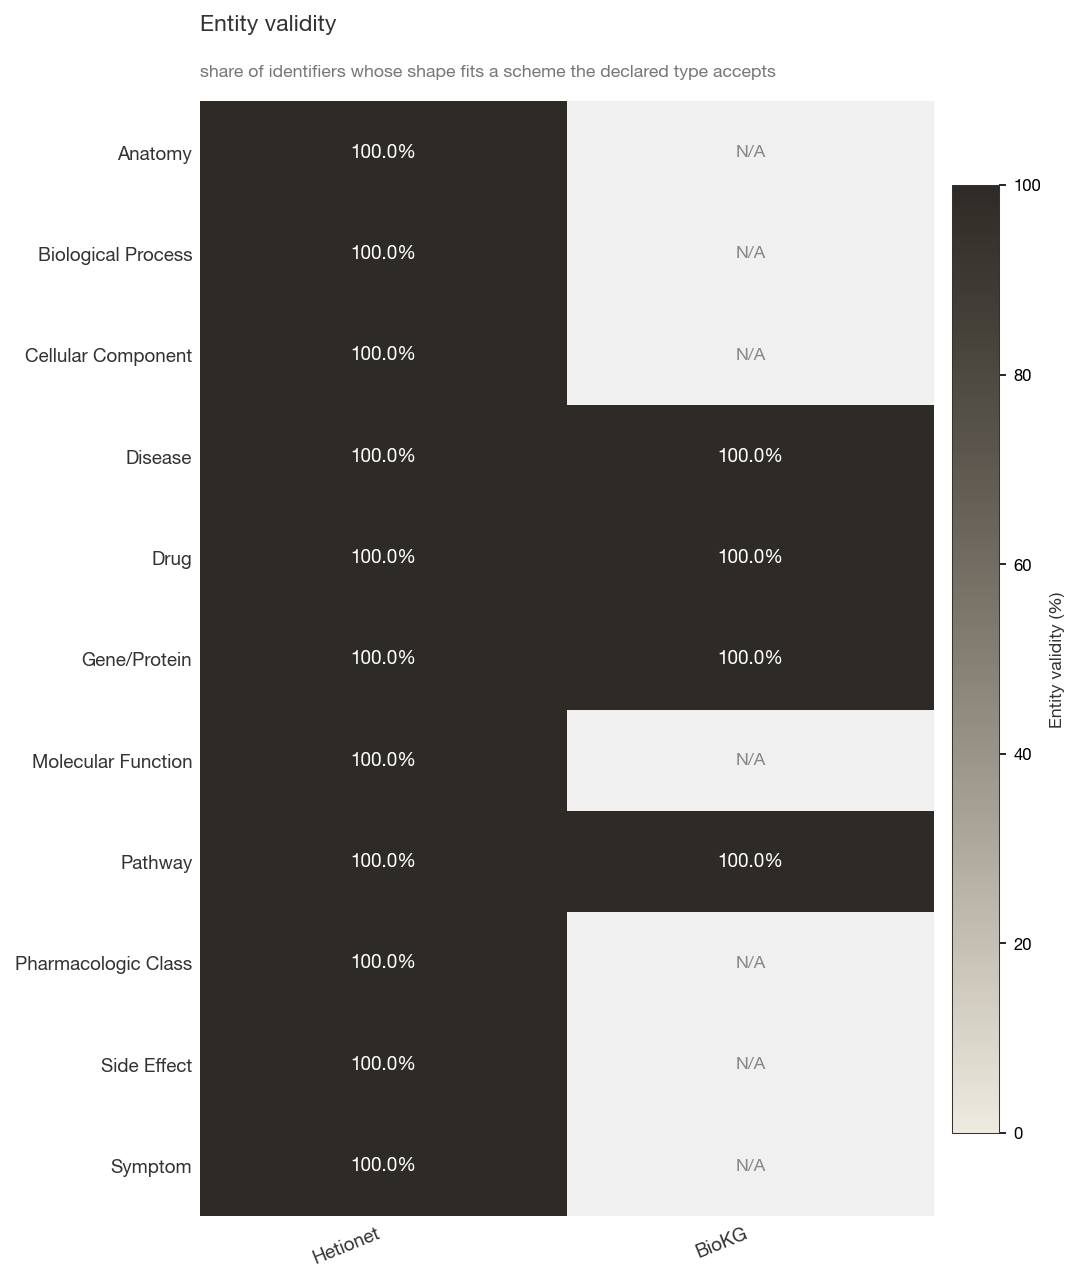

In [6]:
# Pooled to one row per canonical type first: a graph may report a type under
# several declared labels, which cannot be pivoted and must not be double-counted.
pivot_ent = (pool_by_canonical(entity_acc)
             .pivot(index='Canonical', columns='KG', values='Validity (%)')
             .reindex(columns=KG_NAMES))
fig = coverage_heatmap(pivot_ent, 'Entity validity',
                       subtitle='share of identifiers whose shape fits a scheme the declared type accepts',
                       cbar_label='Entity validity (%)')
out.figure(fig, 'entity_validity')
plt.show()

## 2. Relational consistency

For every edge the graph declares two endpoint types. This asks whether the identifiers bear that out, so a relation named for a drug-drug interaction is checked to see that both endpoints really are drugs.

Nothing here asserts what a relation *ought* to join. The edge's own `x_type` and `y_type` are taken as the claim and the identifiers are asked whether the claim holds, so all six graphs are checked by one rule. This replaces the previous per-KG schema declarations, which no well-formed graph could fail.

An endpoint whose KG type label is not mapped to a canonical type in `config/kgs.yaml` is out of scope, and its edge is excluded rather than counted as conforming. On BioKG that is `Complex` and `GeneticDisorder`; the breakdown below names the costliest per graph.

In [7]:
relation_acc = relational_consistency(kgs, ENTITY_TYPE_MAP, RESOLVED_TYPES, schemes)
out.table(relation_acc, 'relational_consistency')

# Worst offenders first: a relation whose endpoints contradict its own typing is
# the finding, and `Top mismatch` names what the endpoint actually resolved to.
display(relation_acc[relation_acc['Checkable'] > 0]
        .sort_values('Consistency (%)')
        .head(25).set_index(['KG', 'Relation']))

Edges  Checkable  Conforming  \
KG       Relation                                                      
hetionet GpBP                          559504     559504      559504   
         GpPW                           84372      84372       84372   
         CcSE                          138944     138944      138944   
         AeG                           526407     526407      526407   
biokg    DRUG_TARGET                    15231      15231       15231   
         DRUG_CARRIER                     804        804         804   
         DRUG_ENZYME                     5077       5077        5077   
         DRUG_TRANSPORTER                3040       3040        3040   
         RELATED_GENETIC_DISORDER        3894       3894        3894   
         DRUG_DISEASE_ASSOCIATION       66867      66867       66867   
         PROTEIN_PATHWAY_ASSOCIATION   250118     250118      250118   
         DISEASE_PATHWAY_ASSOCIATION     3544       3544        3544   
         DISEASE_GENETIC_DISORDER        4882       4882        4882   
         PPI                           113817     113817      113817   
         DDI                          1334085    1334085     1334085   
         DRUG_PATHWAY_ASSOCIATION        5114       5114        5114   
hetionet DuG                             7731       7731        7731   
         CdG                            21102      21102       21102   
         Gr>G                          265672     265672      265672   
         GpCC                           73566      73566       73566   
         GiG                           147164     147164      147164   
         CrC                             6486       6486        6486   
         DdG                             7623       7623        7623   
         DpS                             3357       3357        3357   
         DlA                             3602       3602        3602   

                                      Violations  Consistency (%)  \
KG       Relation                                                   
hetionet GpBP                                  0            100.0   
         GpPW                                  0            100.0   
         CcSE                                  0            100.0   
         AeG                                   0            100.0   
biokg    DRUG_TARGET                           0            100.0   
         DRUG_CARRIER                          0            100.0   
         DRUG_ENZYME                           0            100.0   
         DRUG_TRANSPORTER                      0            100.0   
         RELATED_GENETIC_DISORDER              0            100.0   
         DRUG_DISEASE_ASSOCIATION              0            100.0   
         PROTEIN_PATHWAY_ASSOCIATION           0            100.0   
         DISEASE_PATHWAY_ASSOCIATION           0            100.0   
         DISEASE_GENETIC_DISORDER              0            100.0   
         PPI                                   0            100.0   
         DDI                                   0            100.0   
         DRUG_PATHWAY_ASSOCIATION              0            100.0   
hetionet DuG                                   0            100.0   
         CdG                                   0            100.0   
         Gr>G                                  0            100.0   
         GpCC                                  0            100.0   
         GiG                                   0            100.0   
         CrC                                   0            100.0   
         DdG                                   0            100.0   
         DpS                                   0            100.0   
         DlA                                   0            100.0   

                                      Checkable (%) Top mismatch  
KG       Relation                                                 
hetionet GpBP                                 100.0               
         GpPW                 

In [8]:
# Pooled over each graph's checkable edges. The division is guarded: a graph
# with nothing checkable yields NaN rather than inf, because "no edge could be
# checked" is not a score of zero.
per_kg_rel = (relation_acc.groupby('KG')[['Edges', 'Checkable', 'Conforming']]
              .sum().reindex(KG_NAMES))
per_kg_rel['Consistency (%)'] = (
    100 * per_kg_rel['Conforming'] / per_kg_rel['Checkable'].where(per_kg_rel['Checkable'] > 0)).round(2)
per_kg_rel['Checkable (%)'] = (
    100 * per_kg_rel['Checkable'] / per_kg_rel['Edges'].where(per_kg_rel['Edges'] > 0)).round(1)

out.table(per_kg_rel.reset_index(), 'relational_consistency_by_kg')
display(per_kg_rel)

# Why the rest could not be checked. Out-of-scope endpoints and unresolved
# identifiers are different failures with different remedies, and the single
# "checkable %" hides which one dominates.
checkability = checkability_breakdown(kgs, ENTITY_TYPE_MAP, RESOLVED_TYPES, schemes)
out.table(checkability, 'checkability_breakdown')
display(checkability.set_index('KG'))

,Edges,Checkable,Conforming,Consistency (%),Checkable (%)
KG,,,,,
hetionet,2250197,2250197,2250197,100.0,100.0
biokg,2067998,1943782,1943782,100.0,94.0


,Edges,Type out of scope,Out of scope (%),Endpoint unjudgeable,Unjudgeable (%),Checkable,Checkable (%),Costliest out-of-scope types
KG,,,,,,,,
hetionet,2250197,0,0.0,0,0.0,2250197,100.0,
biokg,2067998,124216,6.0,0,0.0,1943782,94.0,"Complex x124,216"


## 3. Diagnostics (not scored)

In [9]:
# The scored metrics are done. Release the resolver and its per-identifier
# tables before the diagnostics, which need only the graphs themselves; holding
# both alongside two 2M-edge graphs is what pushes this kernel over.
for _v in ['RESOLVED_TYPES', 'resolver']:
    globals().pop(_v, None)
gc.collect()

uniqueness = node_index_uniqueness(kgs)
out.table(uniqueness, 'node_index_uniqueness')
display(uniqueness.set_index('KG'))

,Nodes,Unique indices,Collisions,Uniqueness (%)
KG,,,,
hetionet,47031,47031,0,100.0
biokg,105524,105524,0,100.0


In [10]:
# Semantically contradictory relations that must not share an entity pair.
# KG-specific by necessity: only the curator's own vocabulary says which pairs
# are contradictory. Diagnostic only, for the reason given at the top.
EXCLUSIVE_PAIRS = {
    'primekg': [
        ('Indication vs. Contraindication', 'indication',       'contraindication'),
        ('Indication vs. Off-label',        'indication',       'off-label use'),
        ('Contraindication vs. Off-label',  'contraindication', 'off-label use'),
    ],
    'hetionet': [
        ('Treats (CtD) vs. Palliates (CpD)',      'CtD', 'CpD'),
        ('Compound: Up- vs. Downregulates Gene',  'CuG', 'CdG'),
        ('Anatomy:  Up- vs. Downregulates Gene',  'AuG', 'AdG'),
        ('Disease:  Up- vs. Downregulates Gene',  'DuG', 'DdG'),
    ],
    # OpenBioLink drug activation vs. inhibition of the same gene are opposite
    # effects, so any shared pair is a genuine curation conflict.
    'openbilink': [
        ('Activation vs. Inhibition (direct)',  'DRUG_ACTIVATION_GENE', 'DRUG_INHIBITION_GENE'),
        ('Bind-Activate vs. Bind-Inhibit',     'DRUG_BINDACT_GENE',    'DRUG_BINDINH_GENE'),
        ('Bind-Activate vs. Inhibition',       'DRUG_BINDACT_GENE',    'DRUG_INHIBITION_GENE'),
        ('Activation vs. Bind-Inhibit',        'DRUG_ACTIVATION_GENE', 'DRUG_BINDINH_GENE'),
    ],
    # MATRIX (Every Cure / Biolink) therapeutic vs harmful semantics, plus
    # opposing-direction predicate pairs. Co-occurrence on the same
    # (drug, disease) or (entity_a, entity_b) pair signals curation conflict.
    'matrix': [
        ('Treats vs. Contraindicated',         'treats_or_applied_or_studied_to_treat', 'contraindicated_in'),
        ('Treats vs. Causes',                  'treats_or_applied_or_studied_to_treat', 'causes'),
        ('Treats vs. Has-adverse-event',       'treats_or_applied_or_studied_to_treat', 'has_adverse_event'),
        ('Strict treats vs. Contraindicated',  'treats',                                'contraindicated_in'),
        ('Increases vs. Decreases response',   'increases_response_to',                 'decreases_response_to'),
        ('Positive vs. Negative correlation',  'positively_correlated_with',            'negatively_correlated_with'),
    ],
    # BIOKG DrugBank assigns each drug-protein pair to ONE role (target /
    # carrier / enzyme / transporter). Pairs appearing under multiple roles
    # are curation inconsistencies, or legitimate dual-role proteins such as the
    # CYPs. The metric surfaces both, for review rather than for scoring.
    'biokg': [
        ('Target vs. Carrier',     'DRUG_TARGET',  'DRUG_CARRIER'),
        ('Target vs. Enzyme',      'DRUG_TARGET',  'DRUG_ENZYME'),
        ('Target vs. Transporter', 'DRUG_TARGET',  'DRUG_TRANSPORTER'),
        ('Carrier vs. Enzyme',     'DRUG_CARRIER', 'DRUG_ENZYME'),
    ],
}

exclusivity = relation_exclusivity(kgs, EXCLUSIVE_PAIRS)
out.table(exclusivity, 'relation_exclusivity')
display(exclusivity.set_index(['KG', 'Conflict']))

|A|     |B|  Shared pairs  \
KG       Conflict                                                            
hetionet Treats (CtD) vs. Palliates (CpD)        755     390             0   
         Compound: Up- vs. Downregulates Gene  18756   21102             0   
         Anatomy:  Up- vs. Downregulates Gene  97848  102240             0   
         Disease:  Up- vs. Downregulates Gene   7731    7623             0   
biokg    Target vs. Carrier                    15231     804             4   
         Target vs. Enzyme                     15231    5077           106   
         Target vs. Transporter                15231    3040            66   
         Carrier vs. Enzyme                      804    5077             0   

                                               Conflict rate (%)  
KG       Conflict                                                 
hetionet Treats (CtD) vs. Palliates (CpD)                  0.000  
         Compound: Up- vs. Downregulates Gene              0.000  
         Anatomy:  Up- vs. Downregulates Gene              0.000  
         Disease:  Up- vs. Downregulates Gene              0.000  
biokg    Target vs. Carrier                                0.025  
         Target vs. Enzyme                                 0.525  
         Target vs. Transporter                            0.363  
         Carrier vs. Enzyme                                0.000

## Dimension score

$$\text{Annotation accuracy} = \tfrac{1}{2}\left(\text{entity validity} + \text{relational consistency}\right)$$

Entity validity is averaged over canonical types **shared by every graph**, so the comparison is like for like. Relational consistency is pooled over each graph's checkable edges.

A graph with nothing checkable scores `NaN`, not zero: unmeasured is not the same as wrong. A type no node's shape can adjudicate drops out of the mean rather than scoring zero, and the types that did contribute are printed and stored.

The score table carries `nodes_judged_pct` and `edges_checkable_pct`, because a perfect accuracy over a small slice of a graph is a weaker claim than the same number over most of it. **Read them with the score, not after it:** an edge is excluded when either endpoint's KG type is unmapped in `config/kgs.yaml` or its shape matches nothing declared, and a graph cannot be charged for either.

In [ ]:
# Entity validit is averaged over the canonical types every graph shares, so
# the comparison is like for like. A type that resolves for no node at all drops
# out of that mean rather than scoring zero, and the types that did contribute
# are recorded per graph.
POOLED = pool_by_canonical(entity_acc)
SHARED_TYPES = sorted(set.intersection(*(
    set(sub['Canonical']) for _, sub in POOLED.groupby('KG')))) if len(POOLED) else []
print(f'Shared canonical types ({len(SHARED_TYPES)}): {SHARED_TYPES}')

def score_row(kg):
    """One graph's scores, with how much of it the check could see."""
    # One row per canonical type, so the macro-average weights TYPES and not
    # the number of labels a graph happens to spell a type with.
    ent = POOLED[(POOLED['KG'] == kg) & POOLED['Canonical'].isin(SHARED_TYPES)]
    rel = relation_acc[relation_acc['KG'] == kg]
    checkable, conforming = rel['Checkable'].sum(), rel['Conforming'].sum()

    ev = ent['Validity (%)'].mean() / 100 if len(ent) else np.nan
    rc = conforming / checkable if checkable else np.nan
    return {
        'KG':                         kg,
        'annotation_accuracy':        round(np.nanmean([ev, rc]), 4),
        # Table 1's names for the two metrics. nb00 reads these keys.
        'entity_validity':            round(ev, 4),
        'relational_consistency':     round(rc, 4),
        # Coverage of the check itself, carried beside the score so a perfect
        # accuracy over a small slice cannot be mistaken for one over the whole.
        'nodes_judged_pct':  round(100 * (ent['Valid'].sum() + ent['Wrong scheme'].sum())
                                      / ent['Nodes'].sum(), 1) if len(ent) else np.nan,
        # Reported beside the score, never in it. Its complement is the share
        # our reference databases do not carry, not an error rate.
        'registry_confirmed_pct': round(float(
            (ent['Registry confirmed (%)'] * ent['Nodes']).sum()
            / ent.loc[ent['Registry confirmed (%)'].notna(), 'Nodes'].sum()), 1)
            if ent['Registry confirmed (%)'].notna().any() else np.nan,
        'edges_checkable_pct':  round(100 * checkable / rel['Edges'].sum(), 1) if len(rel) else np.nan,
        'scored_types':         sorted(ent.loc[ent['Validity (%)'].notna(), 'Canonical']),
    }

scores = pd.DataFrame([score_row(kg) for kg in KG_NAMES])
summary_scores = dict(zip(scores['KG'], scores['annotation_accuracy']))
sub_scores = scores.set_index('KG').to_dict('index')

out.table(scores.drop(columns='scored_types'), 'dimension_scores')
display(scores.drop(columns='scored_types').set_index('KG'))

Shared canonical types (4): ['Disease', 'Drug', 'Gene/Protein', 'Pathway']


,annotation_accuracy,entity_validity,relational_consistency,nodes_judged_pct,registry_confirmed_pct,edges_checkable_pct
KG,,,,,,
hetionet,1.0,1.0,1.0,100.0,92.9,100.0
biokg,1.0,1.0,1.0,100.0,39.2,94.0


In [12]:
out.checkpoint({
    'summary_scores':      summary_scores,
    'sub_scores':          sub_scores,
    'shared_types':        SHARED_TYPES,
    'entity_validity':     entity_acc.to_dict('records'),
    'relational_consistency': relation_acc.to_dict('records'),
    'node_uniqueness':     uniqueness.to_dict('records'),
    'relation_exclusivity': exclusivity.to_dict('records'),
    'diagnostics_not_scored': ['node_index_uniqueness', 'relation_exclusivity'],
})
print(out.summary())

02_annotation_accuracy: wrote 14 files
  results/checkpoints/02_annotation_accuracy.pkl
  results/figures/02_annotation_accuracy/entity_validity.pdf
  results/figures/02_annotation_accuracy/entity_validity.png
  results/tables/02_annotation_accuracy/checkability_breakdown.csv
  results/tables/02_annotation_accuracy/declared_id_schemes.csv
  results/tables/02_annotation_accuracy/dimension_scores.csv
  results/tables/02_annotation_accuracy/entity_validity.csv
  results/tables/02_annotation_accuracy/identifier_ambiguity.csv
  results/tables/02_annotation_accuracy/node_index_uniqueness.csv
  results/tables/02_annotation_accuracy/relation_exclusivity.csv
  results/tables/02_annotation_accuracy/relational_consistency.csv
  results/tables/02_annotation_accuracy/relational_consistency_by_kg.csv
  results/tables/02_annotation_accuracy/schema_coverage.csv
  results/tables/02_annotation_accuracy/shared_id_shapes.csv


In [13]:
# Free KG state before the next notebook, which loads the same graphs again.
# Without this both sets stay resident and the kernel is OOM-killed.
for _v in ('kgs', 'RESOLVED_TYPES', 'resolver'):
    globals().pop(_v, None)
print(f'Released KG state; {gc.collect():,} objects collected.')
print('\nAnnotation accuracy: ' + '  '.join(f'{k} {v:.4f}' for k, v in summary_scores.items()))

Released KG state; 34 objects collected.

Annotation accuracy: hetionet 1.0000  biokg 1.0000
